In [1]:
# EEG data to predict time sleep data 

In [18]:
import os # method for interacting with the os ( creating/finding files etc)
import glob # finds pathnames using pattern matching rules

import numpy as np
import matplotlib.pyplot as plt 


#store th
import torch 
import torch.nn as nn # for deep learning ( neural networks)

from sklearn.model_selection import train_test_split 
from sklearn.metrics import accuracy_score, classification_report

import mne #eeg package

In [19]:
data_dir = "data/sleep-cassette"

#store the filepath of specfic files join (___, this) as a list. 
psg_files = sorted(glob.glob(os.path.join(data_dir, '*PSG.edf')))
hypnogram_files = sorted(glob.glob(os.path.join(data_dir, '*Hypnogram.edf')))

In [30]:

hypnogram_files[:3]

['data/sleep-cassette/SC4001EC-Hypnogram.edf',
 'data/sleep-cassette/SC4002EC-Hypnogram.edf',
 'data/sleep-cassette/SC4011EH-Hypnogram.edf']

#### Data Exploration

In [31]:
# loading the raw time-series psg data
raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)

/tmp/ipykernel_1444/3324063448.py:2: RuntimeWarning: Channels contain different highpass filters. Highest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_1444/3324063448.py:2: RuntimeWarning: Channels contain different lowpass filters. Lowest filter setting will be stored.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)
/tmp/ipykernel_1444/3324063448.py:2: RuntimeWarning: Highpass cutoff frequency 16.0 is greater than lowpass cutoff frequency 0.7, setting values to 0 and Nyquist.
  raw_edf = mne.io.read_raw_edf(psg_files[0], preload=True, verbose=False)


In [32]:
raw_edf

<RawEDF | SC4001E0-PSG.edf, 7 x 7950000 (79500.0 s), ~424.6 MiB, data loaded>

In [33]:
#getting actual eeg data from th edf file 
eeg_data = raw_edf.get_data()

In [34]:
eeg_data

array([[ 5.01684982e-06, -2.57875458e-06,  1.35970696e-06, ...,
         5.29816850e-06, -4.64175824e-06,  6.61098901e-06],
       [-2.46739927e-06,  1.46739927e-06, -4.09890110e-06, ...,
        -3.04322344e-06, -3.71501832e-06,  1.75531136e-06],
       [ 1.65086691e-05,  1.60158730e-05,  9.60952381e-06, ...,
         6.97306471e-05,  8.05721612e-05,  1.02255189e-04],
       ...,
       [ 3.55200000e-06,  3.55321564e-06,  3.55442478e-06, ...,
         3.54832977e-06,  3.54955549e-06,  3.55077942e-06],
       [ 3.72064516e+01,  3.72051596e+01,  3.72039072e+01, ...,
         3.72105629e+01,  3.72091535e+01,  3.72077830e+01],
       [ 9.20000000e+02,  9.19950203e+02,  9.19892908e+02, ...,
         9.20104028e+02,  9.20076946e+02,  9.20042260e+02]],
      shape=(7, 7950000))

In [36]:
# getting eeg of only first channel 

eeg_channel1 = eeg_data[0]

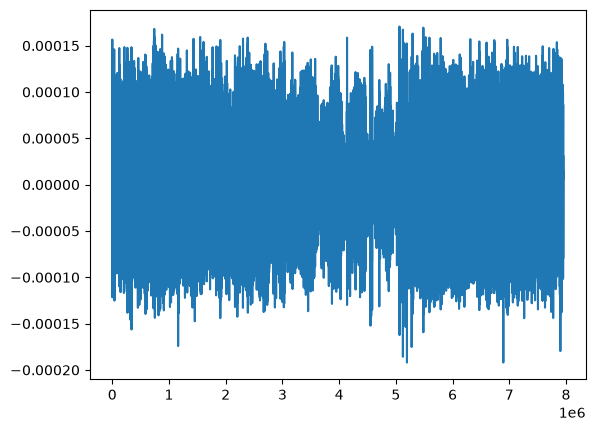

In [37]:
plt.plot(eeg_channel1)